# Experiment 8 — The 9-Qubit Shor Code
**Case Study 5: National Intelligent Transportation System (QML Coursework)**

**Objective:** protect the same angle-encoded traffic qubit as in Experiment 7 against **any** single-qubit error — bit flip
($X$), phase flip ($Z$) or both ($Y$) — using Shor's 9-qubit code. We build and draw the encoder and the error-correcting
decoder, test all 27 possible single-qubit errors, and measure the logical error rate under realistic random (depolarising)
noise, comparing it with an unprotected qubit and with the 3-qubit codes of Experiment 7.

> **Link to Experiment 7:** the bit-flip code ignores phase errors and the phase-flip code ignores bit errors. Real hardware
> produces both. Shor's code is simply the two codes **nested** (concatenated): the phase-flip code on the outside, a bit-flip
> code inside each of its three blocks.

## Aim
To implement Shor's 9-qubit quantum error-correcting code on a qubit carrying a real traffic reading, verify that it corrects
every single-qubit Pauli error, and evaluate its logical error rate and resource cost for the ITS case study.

## Theory
**Encoding.** One logical qubit $\alpha|0\rangle+\beta|1\rangle$ becomes 9 physical qubits:

$$|0_L\rangle=\tfrac{1}{2\sqrt2}(|000\rangle+|111\rangle)^{\otimes3},\qquad
  |1_L\rangle=\tfrac{1}{2\sqrt2}(|000\rangle-|111\rangle)^{\otimes3}$$

$$\alpha|0\rangle+\beta|1\rangle\;\longrightarrow\;\alpha|0_L\rangle+\beta|1_L\rangle$$

* **Step 1 (outer, phase-flip code):** CNOTs from $q_0$ to $q_3,q_6$ and Hadamards → protects against $Z$.
* **Step 2 (inner, bit-flip codes):** inside each block $\{q_0,q_1,q_2\},\{q_3,q_4,q_5\},\{q_6,q_7,q_8\}$, CNOTs copy the basis value → protects against $X$.

**Why it corrects any single error.** $Y = iXZ$, so a $Y$ error is just an $X$ and a $Z$ on the same qubit: the inner code
fixes the $X$ part and the outer code fixes the $Z$ part. Because *any* single-qubit error can be written as a combination
of $I, X, Y, Z$, correcting these four corrects every single-qubit error (error *discretisation*).

**Syndrome information.** The code uses 8 stabilisers: 6 of type $Z_iZ_j$ (bit-flip parity inside each block) and 2 of type
$X^{\otimes6}$ (phase parity between blocks). In this notebook the syndrome is extracted **coherently** with CNOT + Toffoli gates
(the textbook Shor decoder), so no mid-circuit measurement is needed: a Toffoli flips the block leader only when both parity
qubits say "this one is wrong".

**Logical error rate.** With independent errors of probability $p$ per qubit the code fails only when two or more errors hit
in an uncorrectable pattern, so for small $p$: $p_L \approx c\,p^2$ — the error rate is *squared*.

## Case Study 5 — National Intelligent Transportation System (ITS)
A national government is integrating traffic signals, surveillance cameras, GPS devices, emergency vehicles, weather
stations, and autonomous vehicles into one intelligent transportation platform. The platform must continuously:
1. predict traffic flow, 2. optimise signal timing, 3. detect accidents, and 4. recommend alternate routes,

with predictions required within one second.

**Scope of this notebook.** Only the **quantum** layer is error-corrected: one qubit holding an encoded traffic feature
(as produced by $U_{\text{encode}}(x)$ in Experiment 1). Sensors, networks and controllers stay classical.

### Symbol mapping for this experiment
| Symbol | Meaning in this experiment |
|---|---|
| $x$ | One real junction snapshot; we use its `hour` reading |
| $\theta(x)$ | `hour` scaled to $[0,\pi]$ (angle encoding, as in Experiment 1) |
| $\lvert\psi(x)\rangle=R_Y(\theta)\lvert0\rangle=\alpha\lvert0\rangle+\beta\lvert1\rangle$ | The logical traffic qubit to protect |
| $\lvert0_L\rangle,\lvert1_L\rangle$ | The 9-qubit code words that replace $\lvert0\rangle,\lvert1\rangle$ |
| $X_k, Y_k, Z_k$ | Bit-flip / combined / phase-flip error on physical qubit $k$ |
| $Z_iZ_j$, $X^{\otimes 6}$ | Stabilisers: parity checks that reveal the error but not $\alpha,\beta$ |
| $p$ | Physical error probability per qubit (depolarising: $X$, $Y$, $Z$ each with $p/3$) |
| $p_L$ | Logical error probability of the protected traffic qubit |

## 0. Environment setup

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('qiskit_aer') is None:          # installs only on Colab / fresh machines
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'qiskit', 'qiskit-aer', 'pylatexenc', 'ucimlrepo'])

import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
print("qiskit:", qiskit.__version__, "| qiskit-aer:", qiskit_aer.__version__)

qiskit: 2.6.2 | qiskit-aer: 0.18.4


## 1. Dataset and the traffic qubit to protect
**Source:** Metro Interstate Traffic Volume — UCI Machine Learning Repository (id 492, also on Kaggle), the same dataset as
Experiments 1–7. We take the same real 17:00 rush-hour snapshot and angle-encode its `hour` reading.

In [2]:
import os
paths = ['Metro_Interstate_Traffic_Volume.csv', 'data/Metro_Interstate_Traffic_Volume.csv',
         '../data/Metro_Interstate_Traffic_Volume.csv']
local = [p for p in paths if os.path.exists(p)]
if local:
    df = pd.read_csv(local[0])
else:                                                    # Colab: download straight from UCI
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=492); df = pd.concat([d.data.features, d.data.targets], axis=1)

df = df[(df['rain_1h'] < 100) & (df['temp'] > 100)].copy()
df['date_time'] = pd.to_datetime(df['date_time']); df['hour'] = df['date_time'].dt.hour
snap = df[df['hour'] == 17].iloc[0]
theta = snap['hour'] / 23 * np.pi
print(f"snapshot: {snap['date_time']}  hour={snap['hour']}  traffic_volume={snap['traffic_volume']}")
print(f"theta = {theta:.3f} rad  ->  |psi> = {np.cos(theta/2):.3f}|0> + {np.sin(theta/2):.3f}|1>")

snapshot: 2012-10-02 17:00:00  hour=17  traffic_volume=5791
theta = 2.322 rad  ->  |psi> = 0.398|0> + 0.917|1>


## 2. Building the Shor code
### 2.1 Encoder

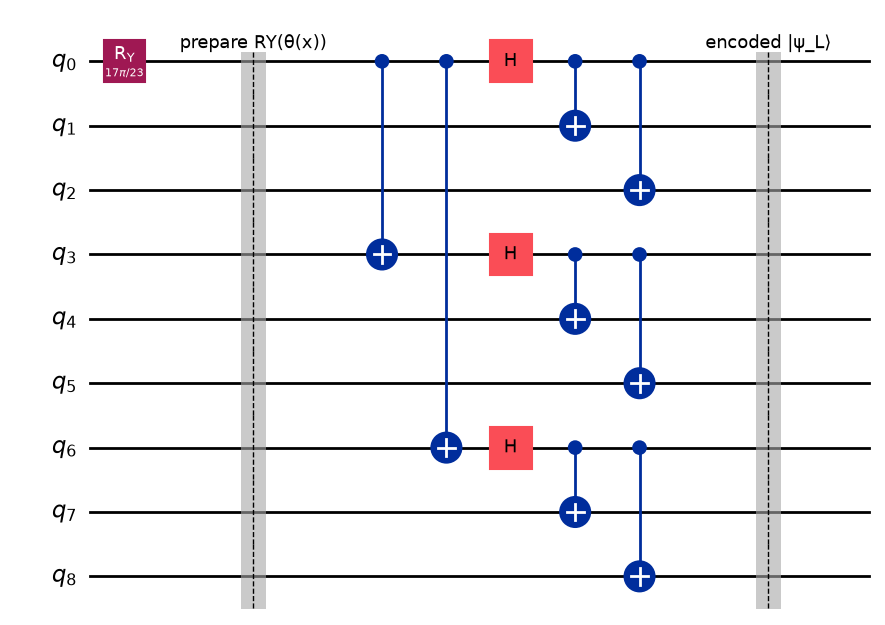

In [3]:
BLOCKS = [(0, 1, 2), (3, 4, 5), (6, 7, 8)]

def shor_encode(qc):
    qc.cx(0, 3); qc.cx(0, 6)                      # outer phase-flip code: spread over 3 blocks
    qc.h([0, 3, 6])
    for a, b, c in BLOCKS:                        # inner bit-flip code inside each block
        qc.cx(a, b); qc.cx(a, c)

def shor_decode_correct(qc):
    for a, b, c in BLOCKS:                        # inner: find & fix one X error per block
        qc.cx(a, b); qc.cx(a, c); qc.ccx(c, b, a)
    qc.h([0, 3, 6])
    qc.cx(0, 3); qc.cx(0, 6); qc.ccx(6, 3, 0)     # outer: find & fix one Z error (now an X)

enc = QuantumCircuit(9, name='Shor encoder')
enc.ry(theta, 0); enc.barrier(label='prepare RY(θ(x))')
shor_encode(enc); enc.barrier(label='encoded |ψ_L⟩')
enc.draw('mpl')

In [4]:
sv = Statevector(enc)
nz = {k: v for k, v in sv.to_dict().items() if abs(v) > 1e-9}
print(f"encoded state has {len(nz)} non-zero amplitudes out of 512")
print("|0_L> and |1_L> use the SAME 8 basis states; they differ only in sign, so each amplitude is (alpha ± beta)/(2*sqrt 2)")
a, b = np.cos(theta / 2), np.sin(theta / 2)
for k, v in list(nz.items())[:4]:
    blocks_111 = sum(k[::-1][3*j:3*j+3] == '111' for j in range(3))      # how many blocks are |111>
    expected = (a + (-1) ** blocks_111 * b) / (2 * np.sqrt(2))
    print(f"  |{k}>  amplitude {v.real:+.4f}   expected {expected:+.4f}")

encoded state has 8 non-zero amplitudes out of 512
|0_L> and |1_L> use the SAME 8 basis states; they differ only in sign, so each amplitude is (alpha ± beta)/(2*sqrt 2)
  |000000000>  amplitude +0.4651   expected +0.4651
  |000000111>  amplitude -0.1834   expected -0.1834
  |000111000>  amplitude -0.1834   expected -0.1834
  |000111111>  amplitude +0.4651   expected +0.4651


### 2.2 Full circuit: prepare → encode → error → decode & correct → check
The **check** undoes $R_Y(\theta)$ on $q_0$: if the traffic qubit was recovered perfectly, $q_0$ is $|0\rangle$ with certainty.
Gate families in the drawing:
* $R_Y(\theta)$ — the **feature-dependent** gate carrying the traffic reading.
* CNOT / H — encoder (entangling gates that spread the information over 9 qubits).
* the single red gate between barriers — the **injected error**.
* CNOT + Toffoli (CCX) — syndrome extraction and correction.

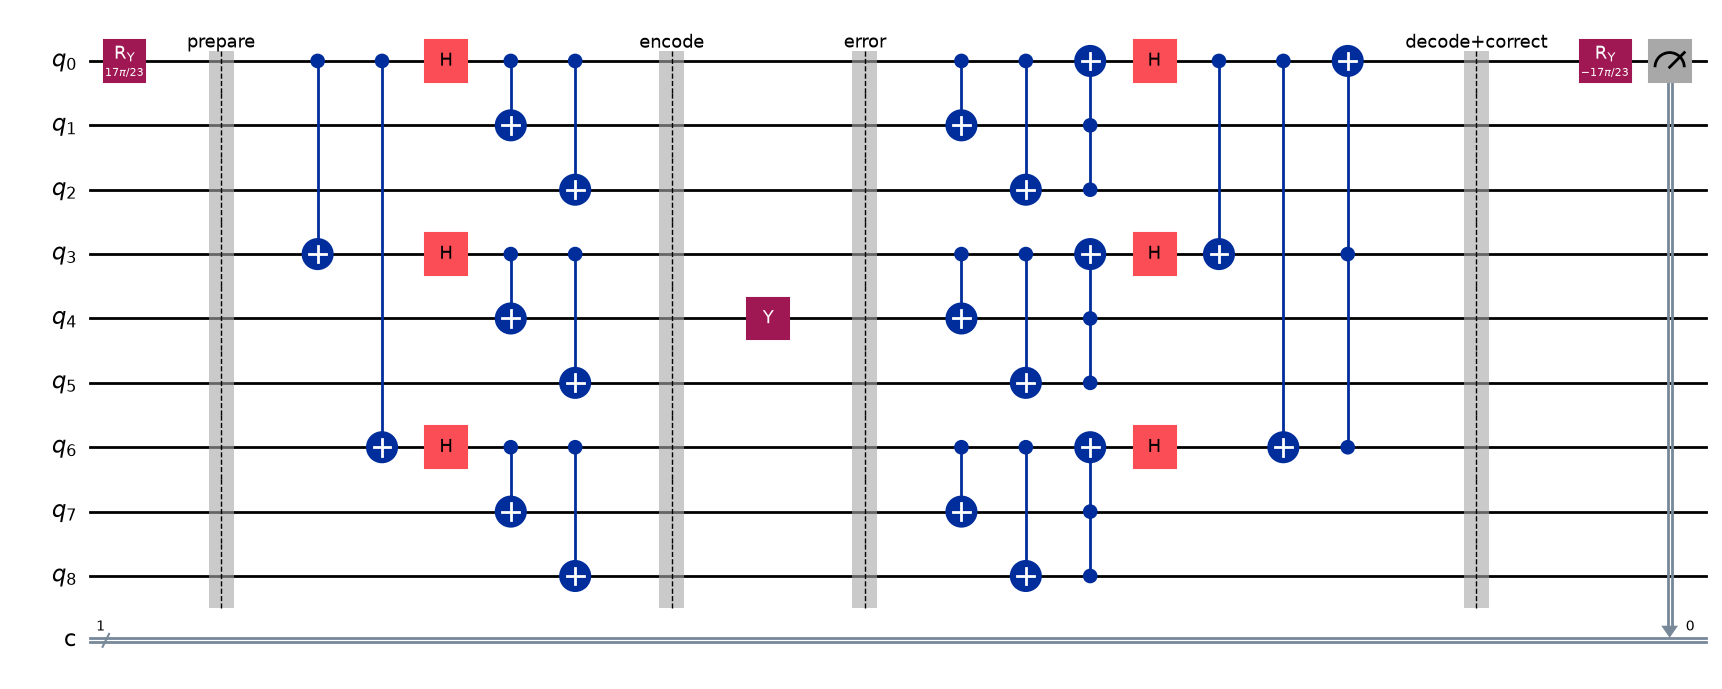

In [5]:
def shor_circuit(theta, error=None, qubit=None, measure=False, wait=False):
    qc = QuantumCircuit(9, 1 if measure else 0)
    qc.ry(theta, 0);              qc.barrier(label='prepare')
    shor_encode(qc);              qc.barrier(label='encode')
    if error is not None:
        getattr(qc, error)(qubit)
    if wait:
        qc.id(range(9))           # noise model acts here (section 4)
    qc.barrier(label='error')
    shor_decode_correct(qc);      qc.barrier(label='decode+correct')
    qc.ry(-theta, 0)
    if measure: qc.measure(0, 0)
    return qc

shor_circuit(theta, 'y', 4, measure=True).draw('mpl', fold=-1)

## 3. Test every single-qubit error (27 cases)
For each error type ($X$, $Y$, $Z$) on each of the 9 qubits we compute — exactly, from the statevector — the probability
that $q_0$ returns to $|0\rangle$, i.e. that the traffic qubit is recovered. As a reference we apply the same three errors to an
**unprotected** traffic qubit.

In [6]:
def p_recovered(qc):
    return Statevector(qc).probabilities([0])[0]

grid = pd.DataFrame(index=['X', 'Y', 'Z'], columns=['bare qubit'] + [f'q{k}' for k in range(9)], dtype=float)
for e in ['x', 'y', 'z']:
    bare = QuantumCircuit(1); bare.ry(theta, 0); getattr(bare, e)(0); bare.ry(-theta, 0)
    grid.loc[e.upper(), 'bare qubit'] = p_recovered(bare)
    for k in range(9):
        grid.loc[e.upper(), f'q{k}'] = p_recovered(shor_circuit(theta, e, k))
print(f"no error: P(recovered) = {p_recovered(shor_circuit(theta)):.3f}")
grid.round(3)

no error: P(recovered) = 1.000


,bare qubit,q0,q1,q2,q3,q4,q5,q6,q7,q8
X,0.534,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Y,0.000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Z,0.466,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


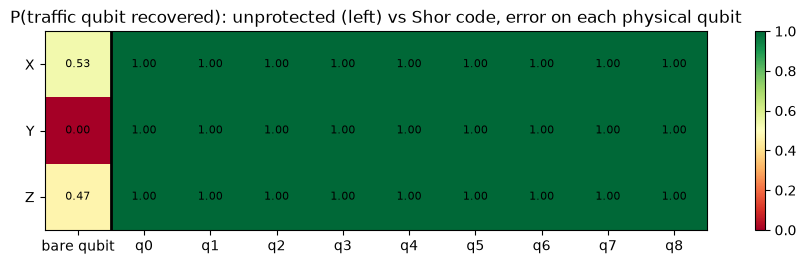

In [7]:
fig, ax = plt.subplots(figsize=(10, 2.6))
im = ax.imshow(grid.values.astype(float), cmap='RdYlGn', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(grid.columns); ax.set_yticks(range(3)); ax.set_yticklabels(grid.index)
ax.axvline(0.5, color='k', lw=2)
ax.set_title('P(traffic qubit recovered): unprotected (left) vs Shor code, error on each physical qubit')
for (i, j), v in np.ndenumerate(grid.values.astype(float)): ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

All 27 single errors are corrected (every Shor cell = 1.00), while the same error on an unprotected qubit damages the
traffic reading badly (a $Y$ error even sends $R_Y(\theta)|0\rangle$ to an orthogonal state, so recovery probability is 0).

## 4. Realistic noise: depolarising errors on all 9 qubits
Now every physical qubit independently suffers a **depolarising** error with probability $p$ (an $X$, $Y$ or $Z$, each with
probability $p/3$). We compare four options for storing the traffic qubit:

| Option | Qubits | Protects against |
|---|---|---|
| Unprotected | 1 | nothing |
| 3-qubit bit-flip code (Exp 7) | 3 | $X$ only |
| 3-qubit phase-flip code (Exp 7) | 3 | $Z$ only |
| 9-qubit Shor code | 9 | $X$, $Y$, $Z$ |

**Counting every logical error.** A leftover logical error can be $X$, $Y$ or $Z$, and a single test state does not reveal all
three. We therefore run three test states: $|0\rangle$ (reveals $X,Y$), $|+\rangle$ (reveals $Y,Z$) and $|{+}i\rangle$ (reveals
$X,Z$). Every logical error is seen by exactly two of them, so $p_L = \tfrac12\,(f_{0}+f_{+}+f_{+i})$, where $f$ is each test's failure rate.

In [8]:
PREP = {'0': [], '+': ['h'], '+i': ['h', 's']}        # gates that prepare each test state from |0>

def with_test_state(body_fn, n, state):
    # prepare test state on q0, run the protection circuit body, undo the preparation, measure q0
    qc = QuantumCircuit(n, 1)
    for g in PREP[state]: getattr(qc, g)(0)
    body_fn(qc)
    for g in reversed(PREP[state]): getattr(qc, g + 'dg' if g == 's' else g)(0)
    qc.measure(0, 0)
    return qc

def body_unprotected(qc): qc.id(0)
def body_shor(qc):
    shor_encode(qc); qc.id(range(9)); shor_decode_correct(qc)
def body_bit(qc):
    qc.cx(0, 1); qc.cx(0, 2); qc.id(range(3)); qc.cx(0, 1); qc.cx(0, 2); qc.ccx(2, 1, 0)
def body_phase(qc):
    qc.cx(0, 1); qc.cx(0, 2); qc.h(range(3)); qc.id(range(3)); qc.h(range(3))
    qc.cx(0, 1); qc.cx(0, 2); qc.ccx(2, 1, 0)

CODES = {'unprotected (1 qubit)': (body_unprotected, 1), 'bit-flip code (3)': (body_bit, 3),
         'phase-flip code (3)': (body_phase, 3), 'Shor code (9)': (body_shor, 9)}

def logical_error_rate(body, n, p, shots=20000):
    nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(4 * p / 3, 1), ['id'])
    # (Qiskit's depolarizing_error(λ) gives X,Y,Z each with prob λ/4, so λ = 4p/3 gives each p/3)
    sim = AerSimulator(noise_model=nm, seed_simulator=1)
    f = [sim.run(with_test_state(body, n, s), shots=shots).result().get_counts().get('1', 0) / shots for s in PREP]
    return 0.5 * sum(f)

ps = [0.001, 0.003, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2]
sweep = pd.DataFrame({'p': ps})
for name, (body, n) in CODES.items():
    sweep[name] = [logical_error_rate(body, n, p) for p in ps]
sweep.round(5)

,p,unprotected (1 qubit),bit-flip code (3),phase-flip code (3),Shor code (9)
0,0.001,0.00090,0.00195,0.00195,0.00000
1,0.003,0.00300,0.00632,0.00632,0.00015
2,0.010,0.01102,0.02058,0.02058,0.00120
3,0.020,0.02122,0.03932,0.03932,0.00572
4,0.030,0.03202,0.05860,0.05860,0.01365
5,0.050,0.05182,0.09555,0.09555,0.03480
6,0.080,0.08138,0.14795,0.14795,0.07748
7,0.120,0.12030,0.20995,0.20995,0.14608
8,0.200,0.20070,0.32683,0.32683,0.31128


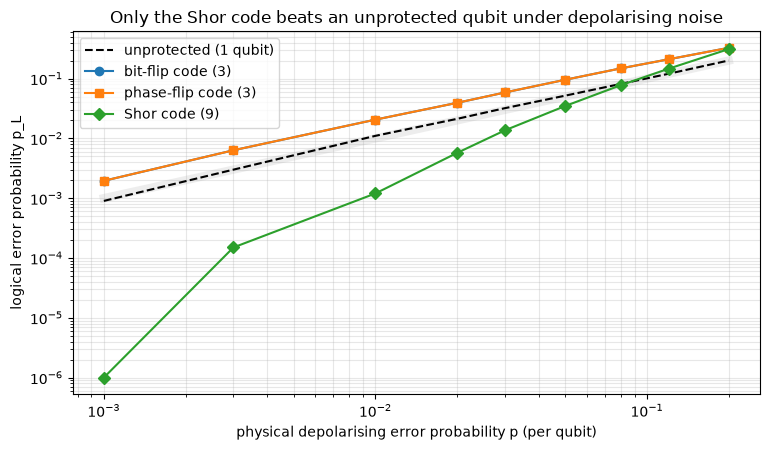

Shor code beats an unprotected qubit up to p ~ 0.08, and loses from p ~ 0.12 (pseudo-threshold between them)
slope of log(p_L) vs log(p) at small p: 1.96  (2 = error rate squared, as theory predicts)


In [9]:
fig, ax = plt.subplots(figsize=(7.8, 4.6))
style = {'unprotected (1 qubit)': 'k--', 'bit-flip code (3)': 'o-', 'phase-flip code (3)': 's-', 'Shor code (9)': 'D-'}
for name in CODES:
    ax.loglog(sweep.p, sweep[name].clip(lower=1e-6), style[name], label=name)
ax.loglog(sweep.p, sweep.p, color='lightgrey', lw=6, alpha=0.4, zorder=0)
ax.set_xlabel('physical depolarising error probability p (per qubit)'); ax.set_ylabel('logical error probability p_L')
ax.set_title('Only the Shor code beats an unprotected qubit under depolarising noise')
ax.legend(); ax.grid(True, which='both', alpha=0.3); plt.tight_layout(); plt.show()

s = sweep['Shor code (9)'].values; u = sweep['unprotected (1 qubit)'].values
i = next(i for i in range(len(ps)) if s[i] > u[i])
print(f"Shor code beats an unprotected qubit up to p ~ {ps[i-1]}, and loses from p ~ {ps[i]} (pseudo-threshold between them)")
use = (sweep.p >= 0.003) & (sweep.p <= 0.03)            # region with enough failures to measure, below threshold
fit = np.polyfit(np.log(sweep.p[use]), np.log(sweep['Shor code (9)'][use]), 1)
print(f"slope of log(p_L) vs log(p) at small p: {fit[0]:.2f}  (2 = error rate squared, as theory predicts)")

## 5. Resource cost — what protection costs the platform

In [10]:
from qiskit import transpile
rows = []
for name, (body, n) in CODES.items():
    qc = QuantumCircuit(n); body(qc)
    ops = qc.count_ops()
    t = transpile(qc, basis_gates=['cx', 'u'], optimization_level=1)
    rows.append({'option': name, 'physical qubits': n, 'CNOT': ops.get('cx', 0), 'Toffoli': ops.get('ccx', 0),
                 'CNOTs after compiling Toffolis': t.count_ops().get('cx', 0), 'depth (compiled)': t.depth()})
cost = pd.DataFrame(rows); display(cost)

print("Scaling to the models of Experiments 5 and 6 (one Shor block per logical qubit):")
for model, nq in [('4-qubit congestion VQC (Exp 5)', 4), ('8-variable QAOA route plan (Exp 6)', 8)]:
    print(f"  {model:36s}: {nq} logical -> {9*nq} physical qubits")

,option,physical qubits,CNOT,Toffoli,CNOTs after compiling Toffolis,depth (compiled)
0,unprotected (1 qubit),1,0,0,0,0
1,bit-flip code (3),3,4,1,10,15
2,phase-flip code (3),3,4,1,10,15
3,Shor code (9),9,16,4,40,29


Scaling to the models of Experiments 5 and 6 (one Shor block per logical qubit):
  4-qubit congestion VQC (Exp 5)      : 4 logical -> 36 physical qubits
  8-variable QAOA route plan (Exp 6)  : 8 logical -> 72 physical qubits


## 6. Discussion
* **Main result.** Shor's code recovered the traffic qubit for **all 27** single-qubit errors (§3), something neither 3-qubit
  code can do. Under random depolarising noise it is the only option that beats an unprotected qubit (§4), and its logical
  error rate grows like $p^2$ instead of $p$ (slope ≈ 2 on the log–log plot).
* **Why the 3-qubit codes are worse than nothing here.** Under depolarising noise the bit-flip code still lets every $Z$ error
  through, and it now has **three** qubits that can receive one, so its logical error rate is *higher* than the bare qubit.
  The same holds for the phase-flip code with $X$ errors. Protection only helps if it matches the noise.
* **Pseudo-threshold.** Somewhere between $p\approx 8\%$ and $12\%$ (§4), two errors in one block become likely and the code starts to
  hurt. Quantum error correction is only worthwhile on hardware whose error rate is already below this level.
* **Cost for the ITS platform.** One logical qubit costs 9 physical qubits, 40 CNOTs and a compiled depth of about 30 (§5), compared with zero gates for the bare qubit. The 4-qubit congestion
  classifier would need 36 physical qubits and the 8-variable route optimiser 72, before counting ancillas for repeated
  syndrome rounds. Deeper circuits also add latency, which matters for the one-second budget.
* **Assumptions.** Noise acts only during one storage window; the encoding and correction gates are assumed perfect. Fault-tolerant
  designs (e.g. surface codes) also handle errors *in* those gates, at a much higher qubit cost.

## 7. Classical vs. quantum: which stages are quantum here?
| Stage | Classical or quantum? |
|---|---|
| Sensor data, cleaning, scaling `hour` → θ | Classical |
| Preparing $R_Y(\theta)\lvert0\rangle$ and Shor encoding | Quantum |
| Depolarising noise | Quantum (hardware effect) |
| Syndrome extraction and correction (CNOT + Toffoli) | Quantum (coherent); on real devices usually measured ancillas + classical decoder |
| Choosing whether QEC is worth it (error rate vs. qubit budget vs. latency) | Classical engineering decision |
| Acting on the prediction (signals, rerouting, alerts) | Classical |

## 8. Summary
* Built and drew the 9-qubit Shor encoder and its CNOT + Toffoli decoder for a real angle-encoded traffic reading.
* Verified that all 27 single-qubit $X$/$Y$/$Z$ errors are corrected, with and without the correction step for comparison.
* Under depolarising noise, only the Shor code beat an unprotected qubit; its logical error rate scales as $p^2$.
* Quantified the cost (9× qubits, 40 CNOTs per logical qubit) and what it means for the ITS quantum modules of Experiments 5 and 6.

**References:** P. W. Shor, "Scheme for reducing decoherence in quantum computer memory," *Phys. Rev. A* 52, R2493, 1995.
M. Nielsen & I. Chuang, *Quantum Computation and Quantum Information*, Ch. 10, 2010. J. Hogue, *Metro Interstate Traffic
Volume*, UCI ML Repository, 2019.